# Scoring et marketing prédictif : segmentation RFM des clients Olist

**Projet de groupe · MSc 2 Data Marketing, INSEEC (2026)**
Ghita El Fathy, Akebrou Aké, Jean-Philippe Nioule, Beni Ambeto

**La demande.** Olist met en relation de petits marchands et les grandes marketplaces brésiliennes. Ses équipes e-commerce veulent une segmentation des clients qu'elles puissent utiliser au quotidien pour leurs campagnes publi-promo, avec :

- une description actionnable de chaque segment et de sa logique ;
- des cibles, des indicateurs prioritaires et des objectifs SMART ;
- une fréquence de mise à jour justifiée ;
- un tableau de bord de suivi ;
- le respect du RGPD.

Le notebook suit l'ordre de la grille d'évaluation : (1) données clés, (2) diagnostic, (3) indicateurs RFM, (4) clustering, (5) description des segments, (6) cibles et objectifs, (7) fréquence de mise à jour, (8) tableau de bord, (9) RGPD, (10) limites.

**Données.** `data/base_donnees_v2.csv` : la base consolidée utilisée par le groupe. Elle est issue du jeu public *Brazilian E-Commerce Public Dataset by Olist* (Kaggle, `olistbr/brazilian-ecommerce`) : les tables commandes, articles, paiements, avis, produits, clients et vendeurs y sont déjà jointes, à raison d'une ligne par article et par paiement.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
sns.set_theme(style="whitegrid")
DATA = "data"
SEED = 42

## 1. Sélection et préparation des données clés

La base contient une ligne par **article commandé et par paiement**. Une commande de trois articles occupe donc trois lignes, et son montant y est répété trois fois. Avant toute analyse, il faut revenir au niveau de la **commande**, puis à celui du **client**.

Deux choix de périmètre :
- **le client** est identifié par `customer_unique_id`. Le champ `customer_id` change à chaque commande : l'utiliser compterait un client fidèle comme plusieurs clients ;
- **seules les commandes livrées** sont retenues. Une commande annulée ne dit rien de la valeur du client.

In [2]:
base = pd.read_csv(f"{DATA}/base_donnees_v2.csv", sep=";")
base = base.drop(columns=[c for c in base.columns if c.startswith("Unnamed")])   # colonne vide créée par le « ; » final

DATES = ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in DATES:
    base[col] = pd.to_datetime(base[col], dayfirst=True)

print(f"{base.shape[0]} lignes, {base.shape[1]} colonnes")
print("Commandes (order_id)         :", base["order_id"].nunique())
print("Clients (customer_unique_id) :", base["customer_unique_id"].nunique())
print("Lignes en double             :", base.duplicated().sum())
print("\nStatut des lignes :")
print(base["order_status"].value_counts().to_string())

74818 lignes, 39 colonnes
Commandes (order_id)         : 65122
Clients (customer_unique_id) : 61043


Lignes en double             : 0

Statut des lignes :
order_status
delivered    74815
canceled         3


### Contrôle qualité : des lignes coupées

Certaines colonnes ont exactement le même nombre de valeurs manquantes. C'est le signe d'un problème de structure plutôt que de vraies données absentes.

In [3]:
manquants = base.isna().sum()
manquants[manquants > 0].sort_values(ascending=False).to_frame("valeurs manquantes")

,valeurs manquantes
review_creation_date,3125
review_answer_timestamp,3125
product_category_name_english,3125
product_name_lenght,3125
product_description_lenght,3125
product_photos_qty,3125
product_weight_g,3125
product_length_cm,3125
product_height_cm,3125
product_width_cm,3125


In [4]:
coupees = base["customer_unique_id"].isna() & base["customer_state"].isna() & base["seller_state"].isna()
print("Lignes coupées :", coupees.sum(), "| commandes touchées :", base.loc[coupees, "order_id"].nunique())
base.loc[coupees, ["order_id", "review_comment_message", "product_category_name_english", "customer_unique_id"]].head(3)

Lignes coupées : 3125 | commandes touchées : 2656


,order_id,review_comment_message,product_category_name_english,customer_unique_id
1,0e7e841ddf8f8f2de2bad69267ecfbcf,"Só achei ela pequena pra seis xícaras ,mais é ...",NaN,NaN
30,c9359e6f27fbe7d1397c40031341540c,A entrega estava prevista para 16/08 e foi ent...,NaN,NaN
48,34280c3bc1c50403f0f1d4b272565256,NaN,NaN,NaN


Dans ces lignes, toutes les colonnes situées après le commentaire de l'avis sont vides : dates de l'avis, produit, catégorie, client, vendeur. Le fichier compte bien une ligne par article (pas de ligne cassée en deux) : les valeurs ont été perdues lors de la préparation de la base, et la cause n'est pas visible dans le fichier. Les colonnes de commande, d'article, de paiement et la note de l'avis restent complètes.

Traitement :
- **pour le diagnostic** (volumes, paiements, notes, délais), ces commandes sont gardées ;
- **pour la segmentation**, il faut savoir à quel client rattacher la commande. On récupère le client sur une autre ligne de la même commande quand elle existe ; sinon, la commande est exclue du RFM.

### Contrôle qualité : le montant payé

Dans une commande, le montant payé doit être à peu près égal à la somme des articles et des frais de port (l'écart vient des intérêts des paiements en plusieurs fois ou des bons d'achat). On compare les deux, commande par commande, selon la position de la commande dans le fichier.

In [5]:
base["ligne_fichier"] = np.arange(len(base)) + 2          # numéro de ligne dans le CSV (ligne 1 = en-tête)
articles = base.drop_duplicates(["order_id", "order_item_id"])
total_articles = articles.groupby("order_id").apply(lambda d: (d["price"] + d["freight_value"]).sum())
total_paye = base.drop_duplicates(["order_id", "payment_sequential"]).groupby("order_id")["payment_value"].sum()

ctrl = pd.DataFrame({"paye": total_paye, "articles_port": total_articles,
                     "ligne": base.groupby("order_id")["ligne_fichier"].min()})
ctrl["ecart"] = ctrl["paye"] / ctrl["articles_port"]
ctrl["bloc de lignes"] = (ctrl["ligne"] // 5000 * 5000).astype(str) + " +"
ctrl.sort_values("ligne").groupby("bloc de lignes", sort=False).agg(
    commandes=("ecart", "size"),
    pct_paiement_incoherent=("ecart", lambda e: ((e > 1.5) | (e < 0.67)).mean() * 100),
    ecart_median=("ecart", "median")).round(2)

,commandes,pct_paiement_incoherent,ecart_median
bloc de lignes,,,
0 +,4968,0.00,1.00
5000 +,4953,0.00,1.00
10000 +,4977,0.00,1.00
15000 +,4969,0.00,1.00
20000 +,4970,0.00,1.00
25000 +,4976,0.00,1.00
30000 +,4971,0.00,1.00
35000 +,4977,0.00,1.00
40000 +,4983,0.00,1.00


In [6]:
print("Première commande incohérente : ligne", ctrl.loc[ctrl["ecart"] > 1.5, "ligne"].min())
print(f"Écart maximal : {ctrl['ecart'].max():.0f} fois le montant des articles et du port")
base.loc[base["ligne_fichier"].between(62000, 62006), ["ligne_fichier", "price", "freight_value", "payment_value"]]

Première commande incohérente : ligne 58270
Écart maximal : 108 fois le montant des articles et du port


,ligne_fichier,price,freight_value,payment_value
61998,62000,37.39,19.04,1 888.54
61999,62001,37.39,19.04,1 888.54
62000,62002,120.00,12.50,6 012.50
62001,62003,35.70,20.80,1 805.80
62002,62004,35.70,20.80,1 805.80
62003,62005,39.90,16.60,2 011.60
62004,62006,39.90,16.60,2 011.60


Jusqu'aux environs de la ligne 58 270, le montant payé correspond aux articles et au port. Ensuite, il est faux pour presque toutes les commandes, jusqu'à plus de 100 fois trop élevé. Les exemples ci-dessus montrent que `payment_value` y vaut **prix × un multiplicateur qui augmente de ligne en ligne + port** : c'est le résultat d'une formule Excel recopiée vers le bas, pas un vrai paiement.

**Décision.** Le montant d'une commande est calculé comme la **somme des prix des articles et des frais de port**. Ces deux colonnes sont cohérentes sur tout le fichier. `payment_value` n'est plus utilisé ; on garde seulement le mode de paiement et le nombre de mensualités.

### Passage au niveau de la commande

- **Montant** : somme de `price` + `freight_value` sur les articles distincts (`order_item_id`) de la commande. Sommer toutes les lignes compterait un article une fois par paiement.
- **Note** : moyenne des avis distincts (`review_id`).
- **Client, État, retard de livraison** : repris de la commande.

In [7]:
livrees = base[base["order_status"] == "delivered"]

pay_cmd = livrees.groupby("order_id").agg(mode_paiement=("payment_type", "first"),
                                          mensualites=("payment_installments", "max"))
pay_cmd["montant"] = total_articles
avis_cmd = livrees.drop_duplicates(["order_id", "review_id"]).groupby("order_id")["review_score"].mean().rename("note")
info_cmd = livrees.groupby("order_id").agg(
    customer_unique_id=("customer_unique_id", "first"),   # « first » ignore les valeurs manquantes
    customer_state=("customer_state", "first"),
    **{c: (c, "first") for c in DATES})

cmd = info_cmd.join(pay_cmd).join(avis_cmd).reset_index()
cmd["retard_j"] = (cmd["order_delivered_customer_date"] - cmd["order_estimated_delivery_date"]).dt.days

print("Commandes livrées       :", len(cmd))
print("  dont sans client      :", cmd["customer_unique_id"].isna().sum())
print("Clients uniques         :", cmd["customer_unique_id"].nunique())
print("Période                 :", cmd["order_purchase_timestamp"].min().date(), "->",
      cmd["order_purchase_timestamp"].max().date())

Commandes livrées       : 65119
  dont sans client      : 2633
Clients uniques         : 61041
Période                 : 2016-10-03 -> 2018-08-29


La table `cmd` (une ligne par commande livrée) sert au diagnostic. La table `cmd_rfm` ne garde que les commandes rattachées à un client : c'est elle qui sert à la segmentation.

In [8]:
cmd_rfm = cmd.dropna(subset=["customer_unique_id"])
print("Commandes utilisées pour le RFM :", len(cmd_rfm), f"({len(cmd_rfm) / len(cmd):.1%} des commandes livrées)")
print("Clients segmentés               :", cmd_rfm["customer_unique_id"].nunique())

Commandes utilisées pour le RFM : 62486 (96.0% des commandes livrées)


Clients segmentés               : 61041


## 2. Diagnostic : ce que disent les transactions

Avant de segmenter, on fait un état rapide de l'activité : volume, saisonnalité, paiement, satisfaction, livraison, géographie et catégories.

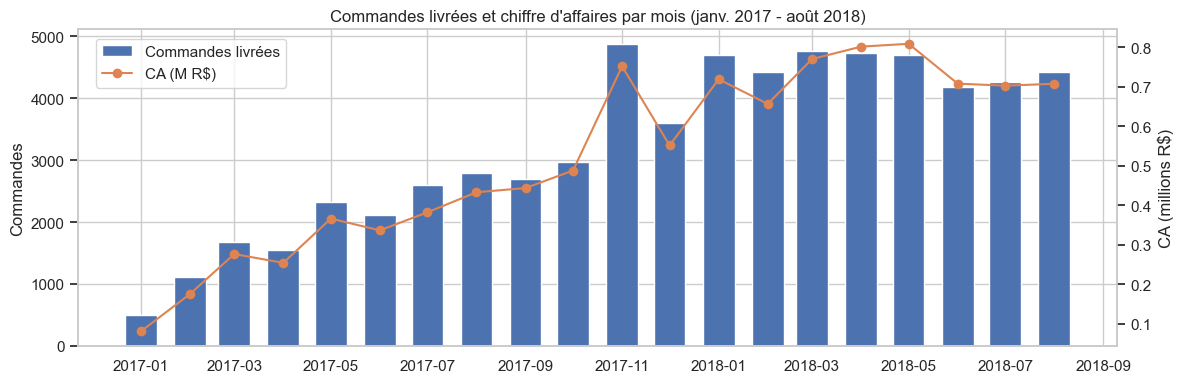

Mois record : November 2017 - 4868 commandes


In [9]:
mois = (cmd.set_index("order_purchase_timestamp")
           .resample("MS").agg(commandes=("order_id", "count"), ca=("montant", "sum")))
mois = mois.loc["2017-01":"2018-08"]   # 2016 : lancement, quelques commandes seulement

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(mois.index, mois["commandes"], width=20, color="#4C72B0", label="Commandes livrées")
ax2 = ax1.twinx()
ax2.plot(mois.index, mois["ca"] / 1e6, color="#DD8452", marker="o", label="CA (M R$)")
ax2.grid(False)
ax1.set_ylabel("Commandes"); ax2.set_ylabel("CA (millions R$)")
ax1.set_title("Commandes livrées et chiffre d'affaires par mois (janv. 2017 - août 2018)")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.9))
plt.tight_layout(); plt.show()

print("Mois record :", mois["commandes"].idxmax().strftime("%B %Y"), "-", mois["commandes"].max(), "commandes")

In [10]:
diag = {
    "CA total (R$, articles + port)": cmd["montant"].sum(),
    "Panier moyen (R$)": cmd["montant"].mean(),
    "Panier médian (R$)": cmd["montant"].median(),
    "Part carte de crédit (%)": (cmd["mode_paiement"] == "credit_card").mean() * 100,
    "Mensualités moyennes (carte)": cmd.loc[cmd["mode_paiement"] == "credit_card", "mensualites"].mean(),
    "Note moyenne (/5)": cmd["note"].mean(),
    "Part de notes 1 ou 2 (%)": (cmd["note"] <= 2).mean() * 100,
    "Part livrée en retard (%)": (cmd["retard_j"] > 0).mean() * 100,
    "Part clients de São Paulo (%)": (cmd_rfm.drop_duplicates("customer_unique_id")["customer_state"] == "SP").mean() * 100,
}
pd.Series(diag).round(1).to_frame("valeur")

,valeur
"CA total (R$, articles + port)",10 454 138.60
Panier moyen (R$),160.50
Panier médian (R$),104.10
Part carte de crédit (%),76.70
Mensualités moyennes (carte),3.60
Note moyenne (/5),4.10
Part de notes 1 ou 2 (%),13.00
Part livrée en retard (%),6.60
Part clients de São Paulo (%),42.30


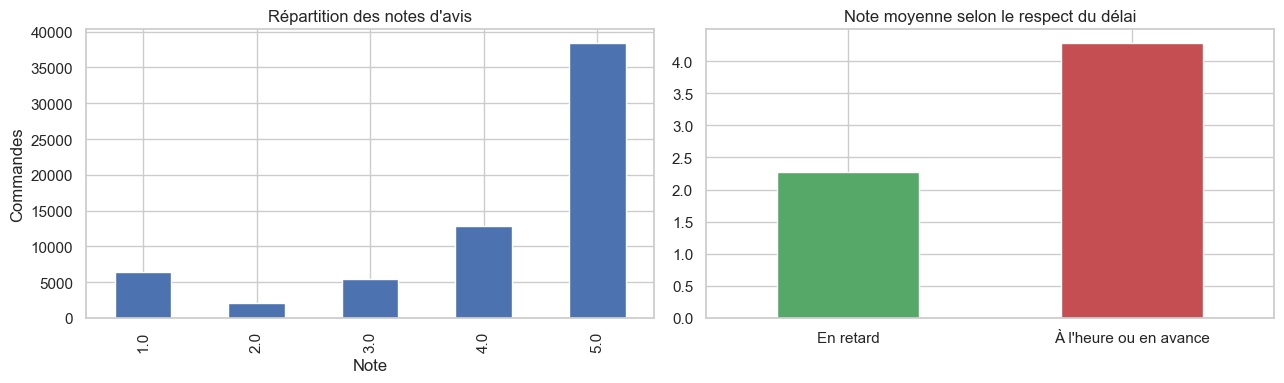

                        mean  count
livraison                          
En retard               2.27   4310
À l'heure ou en avance  4.28  60809


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

cmd["note"].round().value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Répartition des notes d'avis"); axes[0].set_xlabel("Note"); axes[0].set_ylabel("Commandes")

note_retard = cmd.dropna(subset=["retard_j", "note"]).assign(
    livraison=lambda d: np.where(d["retard_j"] > 0, "En retard", "À l'heure ou en avance"))
note_retard.groupby("livraison")["note"].mean().plot.bar(ax=axes[1], color=["#55A868", "#C44E52"])
axes[1].set_title("Note moyenne selon le respect du délai"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print(note_retard.groupby("livraison")["note"].agg(["mean", "count"]).round(2))

In [12]:
art = livrees.drop_duplicates(["order_id", "order_item_id"])   # une ligne par article
top_cat = art.groupby("product_category_name_english")["price"].agg(["count", "sum"]) \
             .sort_values("sum", ascending=False).head(8)
top_cat.columns = ["articles vendus", "CA articles (R$)"]
top_cat

,articles vendus,CA articles (R$)
product_category_name_english,,
health_beauty,6169,789 647.56
watches_gifts,3878,758 742.35
sports_leisure,5543,646 611.73
computers_accessories,5415,640 748.67
bed_bath_table,6425,613 959.64
furniture_decor,5162,440 665.21
housewares,4723,408 746.19
auto,2724,400 526.58


### Forces et faiblesses des données

| Forces | Faiblesses |
|---|---|
| Volume : plus de 65 000 commandes livrées sur près de deux ans | **Très peu de clients reviennent** (voir partie 3) : la fréquence d'achat discrimine mal |
| Données riches : paiement, livraison, avis, géographie, catégories | Aucune donnée socio-démographique (âge, sexe) : segmentation uniquement comportementale |
| Note de satisfaction disponible pour presque toutes les commandes | Forte concentration géographique sur l'État de São Paulo |
| Identifiants déjà pseudonymisés (conformité RGPD facilitée) | Saisonnalité marquée (pic de novembre 2017, Black Friday) qui pèse sur la récence |

Le retard de livraison est l'enseignement opérationnel le plus net : une commande livrée en retard reçoit en moyenne une note inférieure de deux points (tableau ci-dessus).

## 3. Construction des indicateurs RFM

Pour chaque client :
- **R (récence)** : nombre de jours entre son dernier achat et la date de référence (lendemain de la dernière commande du jeu) ;
- **F (fréquence)** : nombre de commandes livrées ;
- **M (montant)** : somme des articles achetés, frais de port compris.

La note moyenne d'avis est calculée en plus. Elle sert à décrire les segments, mais pas à les construire : une segmentation marketing doit refléter la valeur commerciale du client.

In [13]:
DATE_REF = cmd_rfm["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)

def calcul_rfm(commandes, date_ref):
    rfm = commandes.groupby("customer_unique_id").agg(
        derniere=("order_purchase_timestamp", "max"),
        F=("order_id", "nunique"),
        M=("montant", "sum"),
        note=("note", "mean"))
    rfm["R"] = (date_ref - rfm["derniere"]).dt.days
    return rfm[["R", "F", "M", "note"]]

rfm = calcul_rfm(cmd_rfm, DATE_REF)
print("Date de référence :", DATE_REF.date(), "| clients :", len(rfm))
rfm.describe().T

Date de référence : 2018-08-30 | clients : 61041


,count,mean,std,min,25%,50%,75%,max
R,61 041.00,235.56,152.90,0.00,113.00,215.00,345.00,695.00
F,61 041.00,1.02,0.17,1.00,1.00,1.00,1.00,11.00
M,61 041.00,163.65,218.32,10.07,61.96,105.57,182.36,6 726.66
note,61 041.00,4.17,1.26,1.00,4.00,5.00,5.00,5.00


Clients par nombre de commandes :
F
1    59718
2     1226
3       84
4        8
5        3
6        1

Part des clients n'ayant commandé qu'une fois : 97.8%


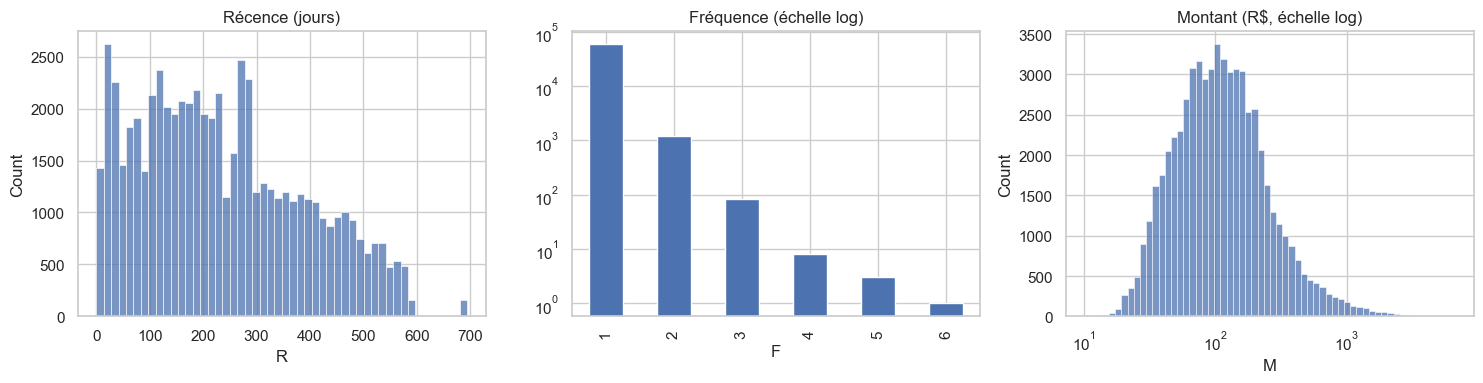

In [14]:
freq = rfm["F"].value_counts().sort_index()
print("Clients par nombre de commandes :")
print(freq.head(6).to_string())
print(f"\nPart des clients n'ayant commandé qu'une fois : {(rfm['F'] == 1).mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(rfm["R"], bins=50, ax=axes[0], color="#4C72B0"); axes[0].set_title("Récence (jours)")
freq.head(6).plot.bar(ax=axes[1], color="#4C72B0", logy=True); axes[1].set_title("Fréquence (échelle log)")
sns.histplot(rfm["M"], bins=60, ax=axes[2], color="#4C72B0", log_scale=True); axes[2].set_title("Montant (R$, échelle log)")
plt.tight_layout(); plt.show()

**Le constat central du projet.** Près de 98 % des clients n'ont acheté qu'une seule fois. Olist est un marché de l'achat ponctuel : la fréquence, qui sert d'habitude à repérer les meilleurs clients, ne distingue ici qu'une petite minorité. On la garde dans le modèle parce que cette minorité est la cible la plus précieuse. Mais la segmentation va surtout s'appuyer sur la récence et le montant.

Le montant est très asymétrique : quelques clients dépensent plusieurs milliers de reais. On applique donc un logarithme avant le clustering, pour que ces clients ne déplacent pas à eux seuls les centres des clusters.

## 4. Clustering K-Means

**Préparation.** Les variables utilisées sont R, log(1 + F) et log(1 + M). Elles sont standardisées (z-score) pour que la récence, exprimée en centaines de jours, ne domine pas les deux autres.

**Choix du nombre de clusters.** On calcule, pour k de 2 à 8 :
- la méthode du coude (inertie) ;
- le score de silhouette, sur un échantillon de 15 000 clients pour limiter le temps de calcul.

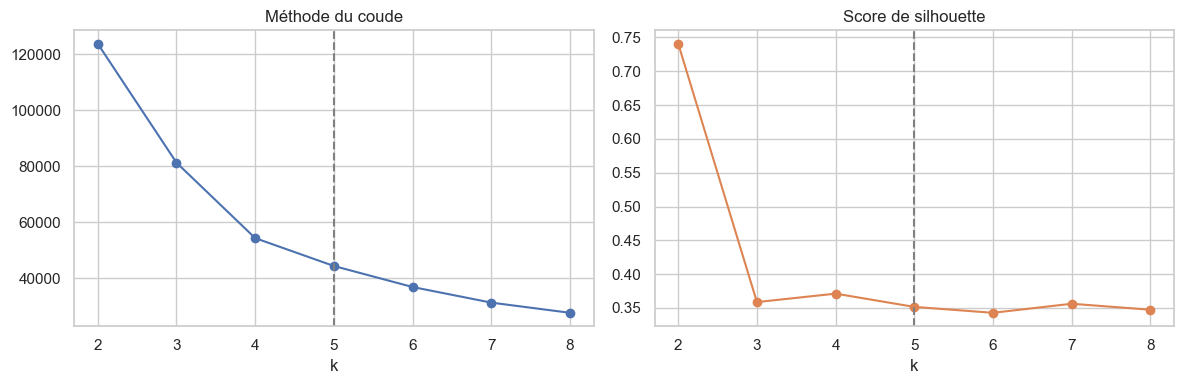

,inertie,silhouette
k,,
2,123 771.71,0.74
3,81 332.69,0.36
4,54 397.95,0.37
5,44 453.19,0.35
6,36 947.40,0.34
7,31 376.43,0.36
8,27 741.43,0.35


In [15]:
X = pd.DataFrame({"R": rfm["R"], "F_log": np.log1p(rfm["F"]), "M_log": np.log1p(rfm["M"])})
X_std = StandardScaler().fit_transform(X)

echant = np.random.RandomState(SEED).choice(len(X_std), 15_000, replace=False)
resultats = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_std)
    resultats.append({"k": k, "inertie": km.inertia_,
                      "silhouette": silhouette_score(X_std[echant], km.labels_[echant])})
choix_k = pd.DataFrame(resultats).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
choix_k["inertie"].plot(marker="o", ax=axes[0]); axes[0].set_title("Méthode du coude")
choix_k["silhouette"].plot(marker="o", ax=axes[1], color="#DD8452"); axes[1].set_title("Score de silhouette")
for ax in axes: ax.axvline(5, ls="--", color="grey")
plt.tight_layout(); plt.show()
choix_k.round(3)

La silhouette la plus haute est obtenue pour k = 2. On vérifie ce que sépare ce découpage :

In [16]:
k2 = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(X_std)
rfm.assign(groupe=k2).groupby("groupe").agg(clients=("F", "size"), part_multi_acheteurs=("F", lambda s: (s > 1).mean()))

,clients,part_multi_acheteurs
groupe,,
0,59718,0.00
1,1323,1.00


Entre k = 4 (meilleure silhouette à partir de k = 3) et k = 5, on compare les profils obtenus :

In [17]:
for k in (4, 5):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_std)
    p = rfm.assign(c=lab).groupby("c").agg(clients=("F", "size"), part_multi=("F", lambda s: (s > 1).mean()),
                                            recence_med=("R", "median"), montant_med=("M", "median"), ca=("M", "sum"))
    p["part_ca"] = p["ca"] / p["ca"].sum() * 100
    print(f"k = {k}"); print(p.drop(columns="ca").sort_values("montant_med").round(2).to_string(), "\n")

k = 4
   clients  part_multi  recence_med  montant_med  part_ca
c                                                        
0    24194        0.00       145.00        66.67    16.93
1    17730        0.00       417.00        96.50    20.99
2    17794        0.00       165.00       215.14    57.83
3     1323        1.00       192.00       231.80     4.25 



k = 5
   clients  part_multi  recence_med  montant_med  part_ca
c                                                        
3    16705        0.00       166.00        52.57     8.87
1    16362        0.00       416.50        90.95    16.77
2    19015        0.00       121.00       143.55    30.18
4     1323        1.00       192.00       231.80     4.25
0     7636        0.00       274.00       383.17    39.93 



**Choix : k = 5.**
- **k = 2 est écarté** malgré sa silhouette élevée : il isole seulement les clients qui ont acheté plusieurs fois (2 %) du reste de la base (98 %). Les deux groupes sont très séparés, mais l'équipe marketing ne peut rien en faire.
- **Coude** : l'inertie baisse fortement jusqu'à k = 4, puis beaucoup plus lentement.
- **Silhouette** : à partir de k = 3, elle reste dans une plage étroite (environ 0,34 à 0,37). k = 4 obtient la meilleure valeur, k = 5 n'est qu'à environ 0,02 derrière.
- **Argument métier** : k = 4 isole déjà les clients qui ont acheté plusieurs fois. k = 5 ajoute une distinction utile : il sépare les **gros paniers** (montant médian de plus de 380 R$, environ 40 % du CA) des clients au panier moyen. C'est la cible prioritaire de la recommandation. Ce gain d'action vaut la petite perte de silhouette.

C'est donc un choix statistique *et* métier : k = 4 serait le choix purement statistique.

Une silhouette autour de 0,35 traduit des segments qui se chevauchent. C'est attendu sur des comportements d'achat continus, sans frontières naturelles. Il faut donc lire les segments comme des profils types, pas comme des groupes étanches.

In [18]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_std)
rfm["cluster"] = km5.labels_

profil = rfm.groupby("cluster").agg(
    clients=("R", "size"), recence_med=("R", "median"), freq_moy=("F", "mean"),
    part_multi=("F", lambda s: (s > 1).mean() * 100), montant_med=("M", "median"),
    ca=("M", "sum"), note_moy=("note", "mean"))
profil["part_clients"] = profil["clients"] / profil["clients"].sum() * 100
profil["part_ca"] = profil["ca"] / profil["ca"].sum() * 100
profil.round(1)

,clients,recence_med,freq_moy,part_multi,montant_med,ca,note_moy,part_clients,part_ca
cluster,,,,,,,,,
0,7636,274.00,1.00,0.00,383.20,3 988 808.40,4.00,12.50,39.90
1,16362,416.50,1.00,0.00,91.00,1 675 389.50,4.20,26.80,16.80
2,19015,121.00,1.00,0.00,143.60,3 014 701.60,4.10,31.20,30.20
3,16705,166.00,1.00,0.00,52.60,886 540.80,4.20,27.40,8.90
4,1323,192.00,2.10,100.00,231.80,424 114.40,4.20,2.20,4.20


**Nommer les clusters.** Les numéros attribués par K-Means sont arbitraires. Les noms sont donc donnés par des règles lues sur les profils, pour que le résultat reste le même si on relance le calcul :

1. le cluster où presque tous les clients ont acheté plusieurs fois → **Fidèles** ;
2. parmi les autres, le montant médian le plus élevé → **Gros paniers** ;
3. la récence médiane la plus élevée → **Inactifs** ;
4. le montant médian le plus faible → **Petits paniers** ;
5. le cluster restant, récent et au panier moyen → **Récents**.

In [19]:
noms = {}
reste = profil.copy()
for nom, critere, plus_grand in [("Fidèles", "part_multi", True), ("Gros paniers", "montant_med", True),
                                 ("Inactifs", "recence_med", True), ("Petits paniers", "montant_med", False)]:
    c = reste[critere].idxmax() if plus_grand else reste[critere].idxmin()
    noms[c] = nom
    reste = reste.drop(c)
noms[reste.index[0]] = "Récents"

ORDRE = ["Fidèles", "Gros paniers", "Récents", "Petits paniers", "Inactifs"]
rfm["segment"] = pd.Categorical(rfm["cluster"].map(noms), categories=ORDRE, ordered=True)
profil = profil.rename(index=noms).loc[ORDRE]
profil.index.name = "segment"
profil.round(1)

,clients,recence_med,freq_moy,part_multi,montant_med,ca,note_moy,part_clients,part_ca
segment,,,,,,,,,
Fidèles,1323,192.00,2.10,100.00,231.80,424 114.40,4.20,2.20,4.20
Gros paniers,7636,274.00,1.00,0.00,383.20,3 988 808.40,4.00,12.50,39.90
Récents,19015,121.00,1.00,0.00,143.60,3 014 701.60,4.10,31.20,30.20
Petits paniers,16705,166.00,1.00,0.00,52.60,886 540.80,4.20,27.40,8.90
Inactifs,16362,416.50,1.00,0.00,91.00,1 675 389.50,4.20,26.80,16.80


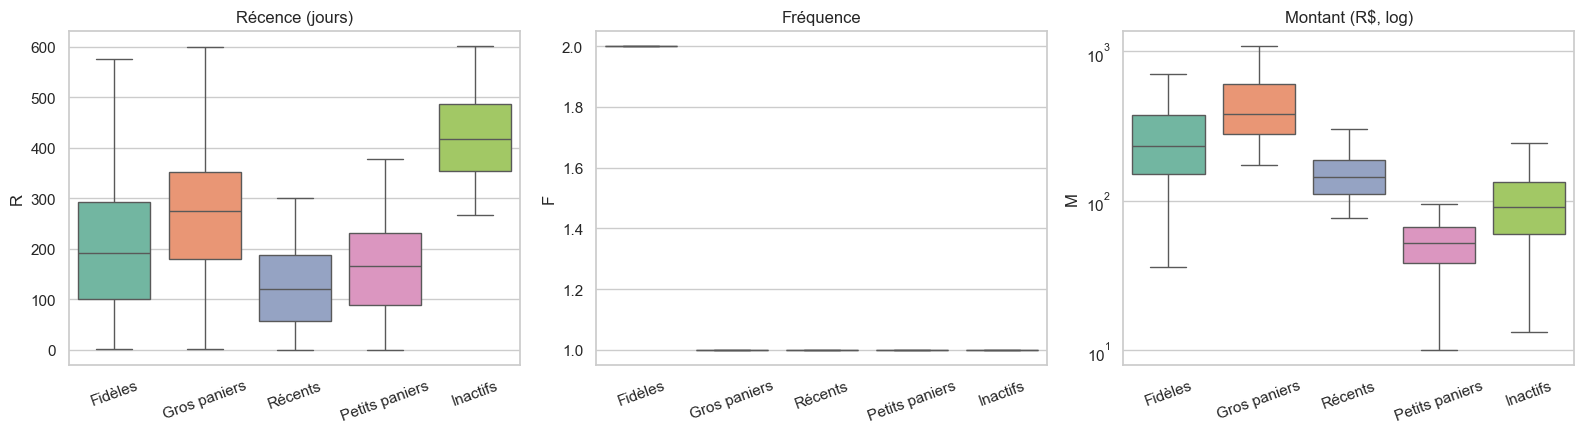

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, var, titre in zip(axes, ["R", "F", "M"], ["Récence (jours)", "Fréquence", "Montant (R$, log)"]):
    sns.boxplot(data=rfm, x="segment", y=var, ax=ax, showfliers=False, palette="Set2")
    ax.set_title(titre); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
axes[2].set_yscale("log")
plt.tight_layout(); plt.show()

## 5. Description actionnable des segments

Le tableau ci-dessous résume chaque segment en chiffres. Il est suivi de l'action marketing proposée pour chacun.

In [21]:
synthese = profil[["clients", "part_clients", "part_ca", "recence_med", "montant_med", "freq_moy", "note_moy"]].copy()
synthese.columns = ["Clients", "% clients", "% CA", "Récence médiane (j)", "Montant médian (R$)",
                    "Commandes / client", "Note moyenne"]
synthese.round(1)

,Clients,% clients,% CA,Récence médiane (j),Montant médian (R$),Commandes / client,Note moyenne
segment,,,,,,,
Fidèles,1323,2.20,4.20,192.00,231.80,2.10,4.20
Gros paniers,7636,12.50,39.90,274.00,383.20,1.00,4.00
Récents,19015,31.20,30.20,121.00,143.60,1.00,4.10
Petits paniers,16705,27.40,8.90,166.00,52.60,1.00,4.20
Inactifs,16362,26.80,16.80,416.50,91.00,1.00,4.20


| Segment | Qui sont-ils ? | Action marketing | Indicateur de suivi |
|---|---|---|---|
| **Fidèles** | Les seuls clients qui ont acheté au moins deux fois ; panier médian élevé | Programme de fidélité, accès anticipé aux nouveautés, recommandations croisées | Taux de 3ᵉ commande |
| **Gros paniers** | Un seul achat, mais le plus gros panier : environ 40 % du CA | Priorité n° 1 : relance personnalisée sur la catégorie achetée, offre de 2ᵉ achat, suivi de satisfaction (leur note est la plus basse) | Taux de 2ᵉ commande à 90 jours |
| **Récents** | Achat récent, panier moyen | Parcours d'accueil : e-mails à J+7 et J+30, enquête post-achat, offre ciblée | Taux de 2ᵉ commande à 90 jours |
| **Petits paniers** | Achat récent à intermédiaire, panier faible | Montée en gamme : frais de port offerts au-delà d'un seuil, lots, ventes croisées | Panier moyen du 2ᵉ achat |
| **Inactifs** | Dernier achat il y a plus d'un an (en médiane) | Une seule campagne de réactivation à faible coût, puis baisse de la pression commerciale | Taux de réactivation, désabonnements |

**Lecture transversale.** Les notes moyennes sont proches d'un segment à l'autre (environ 4,0 à 4,2). L'inactivité ne s'explique donc pas par l'insatisfaction, mais par la nature ponctuelle des achats. La satisfaction dépend surtout du respect du délai de livraison (partie 2).

## 6. Cibles prioritaires et objectifs SMART

L'enjeu commercial d'Olist est le **deuxième achat**. On mesure d'abord le taux actuel : la part des clients qui repassent commande dans les 90 jours suivant leur premier achat (calculée sur les clients dont le premier achat date d'au moins 90 jours).

In [22]:
prem = cmd_rfm.groupby("customer_unique_id")["order_purchase_timestamp"].min().rename("premier")
c2 = cmd_rfm.merge(prem, on="customer_unique_id")
c2 = c2[c2["premier"] <= DATE_REF - pd.Timedelta(days=90)]
deuxieme = c2[(c2["order_purchase_timestamp"] > c2["premier"]) &
              (c2["order_purchase_timestamp"] <= c2["premier"] + pd.Timedelta(days=90))]
taux_2e = deuxieme["customer_unique_id"].nunique() / c2["customer_unique_id"].nunique()
print(f"Taux de 2e commande à 90 jours : {taux_2e:.2%} (clients observables : {c2['customer_unique_id'].nunique()})")

cibles = synthese.loc[["Gros paniers", "Récents", "Fidèles"], ["Clients", "% CA"]]
print("\nCibles prioritaires :")
print(cibles.round(1).to_string())

Taux de 2e commande à 90 jours : 1.12% (clients observables : 48979)

Cibles prioritaires :
              Clients  % CA
segment                    
Gros paniers     7636 39.90
Récents         19015 30.20
Fidèles          1323  4.20


**Priorités.**
1. **Gros paniers** : la plus forte part du CA sur un seul achat. Chaque client qui revient rapporte le plus.
2. **Récents** : le segment le plus nombreux encore « chaud ». C'est le meilleur réservoir de deuxièmes achats.
3. **Fidèles** : petit segment, mais c'est la preuve qu'un réachat est possible. Il faut le protéger.

**Objectifs SMART** (à valider avec l'équipe e-commerce) :

| | Objectif |
|---|---|
| **S**pécifique | Faire repasser commande aux clients des segments Gros paniers et Récents |
| **M**esurable | Doubler le taux de 2ᵉ commande à 90 jours mesuré ci-dessus |
| **A**tteignable | Avec des leviers déjà disponibles et peu coûteux : e-mails automatisés et offre de 2ᵉ achat, sans donnée externe |
| **R**éaliste et pertinent | Avec près de 98 % d'acheteurs ponctuels, quelques points de réachat pèsent directement sur le CA |
| **T**emporel | Sur 6 mois, avec un premier point au bout de 3 mois, au moment de la mise à jour de la segmentation (partie 7) |

Un objectif de satisfaction complète le dispositif : réduire la part de commandes livrées en retard, qui fait perdre en moyenne deux points de note.

## 7. Fréquence de mise à jour : stabilité des segments

Pour décider à quel rythme recalculer la segmentation, on la refait à plusieurs dates, comme si on était à la fin de chaque trimestre. On compare ensuite les segments obtenus pour les clients présents aux deux dates, avec l'**indice de Rand ajusté (ARI)** :
- 1 : les clients restent exactement dans les mêmes groupes ;
- 0 : les groupes changent autant que s'ils étaient tirés au hasard.

Repères utilisés : ARI > 0,70 → stable, mise à jour semestrielle ; 0,50 à 0,70 → mise à jour trimestrielle ; < 0,50 → mise à jour mensuelle.

In [23]:
def segmenter(date_ref):
    sous = cmd_rfm[cmd_rfm["order_purchase_timestamp"] < date_ref]
    r = calcul_rfm(sous, date_ref)
    Z = StandardScaler().fit_transform(np.column_stack([r["R"], np.log1p(r["F"]), np.log1p(r["M"])]))
    return pd.Series(KMeans(n_clusters=5, n_init=10, random_state=SEED).fit_predict(Z), index=r.index)

dates = pd.to_datetime(["2017-09-30", "2017-12-31", "2018-03-31", "2018-06-30"])
seg_dates = {d: segmenter(d) for d in dates}

stab = []
for d1, d2 in zip(dates[:-1], dates[1:]):
    communs = seg_dates[d1].index.intersection(seg_dates[d2].index)
    stab.append({"période": f"{d1.date()} -> {d2.date()}", "clients communs": len(communs),
                 "ARI": adjusted_rand_score(seg_dates[d1][communs], seg_dates[d2][communs])})
stab = pd.DataFrame(stab).set_index("période")
print(f"ARI moyen d'un trimestre à l'autre : {stab['ARI'].mean():.2f}")
stab.round(2)

ARI moyen d'un trimestre à l'autre : 0.61


,clients communs,ARI
période,,
2017-09-30 -> 2017-12-31,16460,0.47
2017-12-31 -> 2018-03-31,27158,0.61
2018-03-31 -> 2018-06-30,40052,0.76


**Conclusion : une mise à jour trimestrielle.** L'ARI moyen d'un trimestre à l'autre se situe dans la zone « mise à jour trimestrielle ». Il augmente d'une période à l'autre (de 0,47 à 0,76), sans doute parce que la base de clients s'agrandit : chaque recalcul porte sur davantage de clients déjà connus. Les segments évoluent sensiblement, surtout parce que la récence de chaque client augmente mécaniquement avec le temps : un client « Récent » devient « Inactif » s'il ne rachète pas. Un recalcul tous les trois mois, automatisé avec ce notebook, suffit. Le modèle lui-même (nombre de segments, variables) n'a besoin d'être revu qu'une fois par an.

## 8. Tableau de bord et export pour l'équipe marketing

Le tableau de bord résume en une image ce que l'équipe marketing doit suivre. Le fichier `outputs/segments_clients.csv` donne le segment de chaque client, pour l'importer dans l'outil d'e-mailing ou dans Power BI.

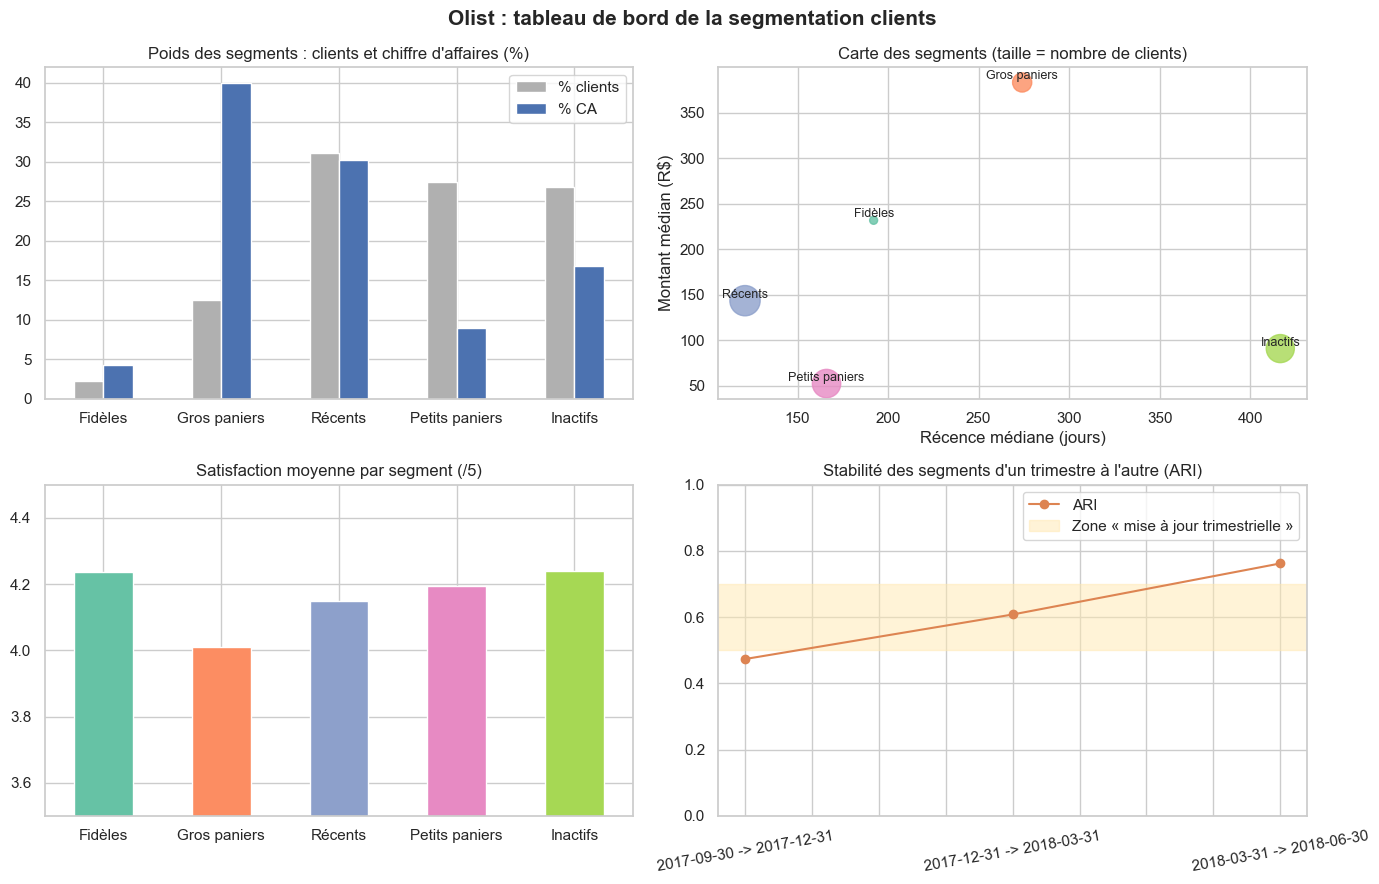

In [24]:
couleurs = dict(zip(ORDRE, sns.color_palette("Set2", 5)))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

synthese[["% clients", "% CA"]].plot.bar(ax=axes[0, 0], color=["#B0B0B0", "#4C72B0"])
axes[0, 0].set_title("Poids des segments : clients et chiffre d'affaires (%)")
axes[0, 0].tick_params(axis="x", rotation=0); axes[0, 0].set_xlabel("")

axes[0, 1].scatter(synthese["Récence médiane (j)"], synthese["Montant médian (R$)"],
                   s=synthese["Clients"] / 40, c=[couleurs[s] for s in synthese.index], alpha=.8)
for s, r in synthese.iterrows():
    axes[0, 1].annotate(s, (r["Récence médiane (j)"], r["Montant médian (R$)"]), ha="center", va="bottom", fontsize=9)
axes[0, 1].set_xlabel("Récence médiane (jours)"); axes[0, 1].set_ylabel("Montant médian (R$)")
axes[0, 1].set_title("Carte des segments (taille = nombre de clients)")

synthese["Note moyenne"].plot.bar(ax=axes[1, 0], color=[couleurs[s] for s in synthese.index])
axes[1, 0].set_ylim(3.5, 4.5); axes[1, 0].set_title("Satisfaction moyenne par segment (/5)")
axes[1, 0].tick_params(axis="x", rotation=0); axes[1, 0].set_xlabel("")

stab["ARI"].plot(marker="o", ax=axes[1, 1], color="#DD8452")
axes[1, 1].axhspan(0.5, 0.7, color="#FFE8B0", alpha=.5, label="Zone « mise à jour trimestrielle »")
axes[1, 1].set_ylim(0, 1); axes[1, 1].set_title("Stabilité des segments d'un trimestre à l'autre (ARI)")
axes[1, 1].tick_params(axis="x", rotation=10); axes[1, 1].set_xlabel(""); axes[1, 1].legend()

fig.suptitle("Olist : tableau de bord de la segmentation clients", fontsize=15, weight="bold")
plt.tight_layout()
plt.savefig("outputs/dashboard_segments.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
export = rfm[["segment", "R", "F", "M", "note"]].rename(columns={
    "R": "recence_jours", "F": "nb_commandes", "M": "montant_total", "note": "note_moyenne"})
export.to_csv("outputs/segments_clients.csv")
synthese.round(2).to_csv("outputs/synthese_segments.csv")
print("Exporté :", len(export), "clients ->", "outputs/segments_clients.csv")

Exporté : 61041 clients -> outputs/segments_clients.csv


## 9. Conformité RGPD

- **Minimisation** : seules des données d'achat sont utilisées (dates, montants, notes, État). Aucun nom, e-mail ni téléphone.
- **Pseudonymisation** : les identifiants clients sont des codes hachés fournis par Olist. Le fichier exporté ne contient que ce code, le segment et les indicateurs RFM.
- **Finalité** : le ciblage des campagnes marketing, et rien d'autre. Toute autre utilisation demanderait une nouvelle analyse.
- **Base légale** : intérêt légitime pour la segmentation ; consentement préalable pour les envois d'e-mails ou de SMS.
- **Droits des personnes** : un client qui s'oppose au profilage est retiré de l'export au recalcul suivant. Un lien de désinscription figure dans chaque message.
- **Conservation** : segments recalculés chaque trimestre ; historique limité à 3 ans après le dernier achat.

Les clients étant brésiliens, la LGPD (loi brésilienne, très proche du RGPD) s'applique également.

## 10. Limites

- **Base partielle.** La base V2 contient environ deux tiers des commandes du jeu Olist complet, réparties de façon régulière dans le temps. Les proportions (part des acheteurs uniques, notes, récence) restent représentatives, mais les volumes (clients, CA) ne correspondent pas à l'activité totale d'Olist.
- **Montants payés inutilisables** sur la fin du fichier (partie 1) : le montant est recalculé à partir des prix et du port, ce qui ignore les intérêts des paiements en plusieurs fois et les bons d'achat.
- **Lignes coupées.** Une partie des commandes n'a pas pu être rattachée à un client (partie 1) et manque à la segmentation.
- **Articles manquants.** Comparée au jeu Kaggle d'origine, la base V2 omet une partie des articles de 755 commandes (environ 1 %) : leur montant est sous-estimé.
- **Silhouette modérée (environ 0,35).** Les segments se chevauchent. Ce sont des profils de travail, pas des catégories naturelles.
- **Fréquence peu discriminante.** Avec près de 98 % d'acheteurs uniques, le score F classique (de 1 à 5) n'a pas de sens ici. Seul le segment Fidèles l'exploite.
- **Pas de variables socio-démographiques.** On ne peut pas expliquer *qui* sont les clients, seulement *comment* ils achètent.
- **Effet de date.** La récence dépend de la date de référence. La saisonnalité (Black Friday 2017) gonfle mécaniquement certains segments.
- **Objectifs non testés.** Le doublement du taux de 2ᵉ achat est une cible à valider par un test A/B (groupe contacté contre groupe témoin) avant d'être généralisée.